In [1]:
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

In [2]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

In [3]:
conn = sqlite3.connect(database='mayank_sales.db',check_same_thread=False)

In [4]:
checkpoint = SqliteSaver(conn=conn)

In [5]:
load_dotenv()

True

In [6]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

In [7]:
prompt = ChatPromptTemplate([
    ('system','you are a helpful assistant for a e-commerce website called mayank-sales and you have to deal with the user'),
    ('human','{history}')
])

In [8]:
parser = StrOutputParser()

In [9]:
chain = prompt | model

In [10]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated,Literal

In [11]:
from langgraph.graph.message import BaseMessage,add_messages

In [26]:
from langchain_core.messages import RemoveMessage

In [ ]:
class chat(TypedDict):
    history : Annotated[list[BaseMessage],add_messages]
    summary : str

In [13]:
def chating(state : chat):
    history = state['history']
    r = chain.invoke({
        'history' : history
    })
    return {'history': [r]}

In [14]:
graph = StateGraph(chat)

In [15]:
graph.add_node('chating',chating)

In [16]:
graph.add_edge(START,'chating')
graph.add_edge('chating',END)

In [17]:
config = {'configurable': 
          {'thread_id' : 1}}

In [18]:
wk = graph.compile(checkpointer=checkpoint)

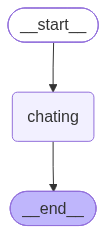

In [19]:
wk

In [20]:
while True:
    q = input('enter your query: ')
    print(f'YOU : {q}')
    if q == 'q':
        break
    r = wk.invoke({'history' : q},config=config)
    print(f'AI : {r['history'][-1].content}')

YOU : hii mate do you recognise me
AI : Yes, Duryo! I recognize you. You mentioned your name earlier in our conversation.

How can I help you today at Mayank-Sales?
YOU : i want the shoes of campus sports
AI : Great, Duryo! You're looking for shoes from **Campus Sports**.

Campus is a popular brand, and they make a variety of sports shoes. To help me find the perfect pair for you, could you tell me a little more about what you're looking for? For example:

*   **What type of sport or activity** are they for (running, training, casual wear, etc.)?
*   **What size** are you looking for?
*   **Do you have any preferred colors or styles** in mind?

Let me know, and I'll check our inventory for Campus Sports shoes!
YOU : under 700 fo running on roads
AI : Okay, Duryo! You're looking for **Campus Sports running shoes, specifically for road running, and with a budget under ₹700.**

That's a very specific request, and finding dedicated running shoes from a brand like Campus under ₹700 might be